In [1]:
'''
match light curves to initial CNN results and map what gets cut
'''

'\nmatch light curves to initial CNN results and map what gets cut\n'

In [54]:
import numpy as np
import pandas as pd
from astropy.io import fits
import os
import review_findings_functions as rff
import glob
import matplotlib.pyplot as plt

In [3]:
# folder path where the initial DataFrames are stored
folder_path = "/lustre/lrspec/ZTF_data/science_extractions/1020"
direcname = "1020"
fpath = (
    "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
    + direcname
    + "_minus_extras/"
)

print("listing files", flush=True)
# List all the files in the folder
files = [
    f for f in os.listdir(folder_path) if f.endswith("alllist")
]

listing files


In [109]:
files[:15]

['ztf_20221020154120_000640_zi_c14_x_0001.fits.fz2alllist',
 'ztf_20221020138241_000686_zi_c16_x_0005.fits.fz4alllist',
 'ztf_20221020157697_000640_zi_c08_x_0015.fits.fz1alllist',
 'ztf_20221020138241_000686_zi_c08_x_0022.fits.fz1alllist',
 'ztf_20221020141806_000686_zi_c06_x_0016.fits.fz2alllist',
 'ztf_20221020148032_000686_zg_c11_x_0005.fits.fz4alllist',
 'ztf_20221020294271_000449_zr_c02_x_0011.fits.fz2alllist',
 'ztf_20221020297847_000449_zr_c07_x_0017.fits.fz1alllist',
 'ztf_20221020294271_000449_zr_c09_x_0019.fits.fz1alllist',
 'ztf_20221020163819_000640_zg_c10_x_0008.fits.fz1alllist',
 'ztf_20221020297847_000449_zr_c08_x_0026.fits.fz2alllist',
 'ztf_20221020294271_000449_zr_c06_x_0028.fits.fz2alllist',
 'ztf_20221020163819_000640_zg_c06_x_0002.fits.fz4alllist',
 'ztf_20221020138241_000686_zi_c13_x_0008.fits.fz3alllist',
 'ztf_20221020157697_000640_zi_c04_x_0001.fits.fz1alllist']

In [6]:
lightcurve_directory = '/lustre/lrspec/ZTF_data/lightcurves/1020/'
lightcurve_files = os.listdir(lightcurve_directory)

In [110]:
lightcurve_files[:15]

['lightcurve_ztf_20221020138241_000686_zi_c14_x_0023_4_2015_1263.csv',
 'lightcurve_ztf_20221020138241_000686_zi_c12_x_0002_4_2561_0887.csv',
 'lightcurve_ztf_20221020141806_000686_zi_c06_x_0024_4_2703_1717.csv',
 'lightcurve_ztf_20221020148032_000686_zg_c12_x_0025_4_2864_2400.csv',
 'lightcurve_ztf_20221020297847_000449_zr_c14_x_0004_4_2461_2125.csv',
 'lightcurve_ztf_20221020163819_000640_zg_c15_x_0010_1_2555_2959.csv',
 'lightcurve_ztf_20221020154120_000640_zi_c04_x_0022_4_0408_0918.csv',
 'lightcurve_ztf_20221020138241_000686_zi_c07_x_0016_3_1714_0792.csv',
 'lightcurve_ztf_20221020148032_000686_zg_c05_x_0021_2_0955_1635.csv',
 'lightcurve_ztf_20221020148032_000686_zg_c02_x_0017_3_2655_1908.csv',
 'lightcurve_ztf_20221020138241_000686_zi_c06_x_0026_3_0995_0236.csv',
 'lightcurve_ztf_20221020157697_000640_zi_c16_x_0019_4_2834_0117.csv',
 'lightcurve_ztf_20221020154120_000640_zi_c08_x_0023_4_2531_1307.csv',
 'lightcurve_ztf_20221020141806_000686_zi_c07_x_0010_3_2294_1272.csv',
 'ligh

In [105]:
df = get_initial_df_for_lc(lightcurve_files[14])

ztf_20221020148032_000686_zg_c16_x_0018.fits.fz4alllist


In [106]:
df

,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size
101,101,ztf_20221020148032_000686_zg_c16_x_0018.,pos,1135.500000,2633.000000,6
476,476,ztf_20221020148032_000686_zg_c16_x_0018.,neg,1127.384615,2631.461538,13
480,480,ztf_20221020148032_000686_zg_c16_x_0018.,neg,1143.500000,2631.500000,14
588,588,ztf_20221020148032_000686_zg_c16_x_0018.,neg,1724.500000,2632.500000,4
648,648,ztf_20221020148032_000686_zg_c16_x_0018.,neg,2065.333333,2632.666667,3
790,790,ztf_20221020148032_000686_zg_c16_x_0018.,neg,2876.500000,2633.000000,2


In [104]:
for i in range(30):
    df = get_initial_df_for_lc(lightcurve_files[i])
    print(len(df))

ztf_20221020138241_000686_zi_c14_x_0023.fits.fz4alllist
0
ztf_20221020138241_000686_zi_c12_x_0002.fits.fz4alllist
0
ztf_20221020141806_000686_zi_c06_x_0024.fits.fz4alllist
0
ztf_20221020148032_000686_zg_c12_x_0025.fits.fz4alllist
0
ztf_20221020297847_000449_zr_c14_x_0004.fits.fz4alllist
0
ztf_20221020163819_000640_zg_c15_x_0010.fits.fz1alllist
0
ztf_20221020154120_000640_zi_c04_x_0022.fits.fz4alllist
0
ztf_20221020138241_000686_zi_c07_x_0016.fits.fz3alllist
0
ztf_20221020148032_000686_zg_c05_x_0021.fits.fz2alllist
0
ztf_20221020148032_000686_zg_c02_x_0017.fits.fz3alllist
0
ztf_20221020138241_000686_zi_c06_x_0026.fits.fz3alllist
0
ztf_20221020157697_000640_zi_c16_x_0019.fits.fz4alllist
0
ztf_20221020154120_000640_zi_c08_x_0023.fits.fz4alllist
0
ztf_20221020141806_000686_zi_c07_x_0010.fits.fz3alllist
0
ztf_20221020148032_000686_zg_c16_x_0018.fits.fz4alllist
6
ztf_20221020148032_000686_zg_c08_x_0022.fits.fz3alllist
0
ztf_20221020141806_000686_zi_c01_x_0020.fits.fz3alllist
172
ztf_20221020

In [70]:
np.min(df['col_from_nn'][:-1]), np.max(df['col_from_nn'])

(402.8888888888889, 1463.0)

(array([  1.,   0.,  15.,   0.,   0.,   0.,   0.,   0.,   0., 192.]),
 array([   0. ,  146.3,  292.6,  438.9,  585.2,  731.5,  877.8, 1024.1,
        1170.4, 1316.7, 1463. ]),
 <BarContainer object of 10 artists>)

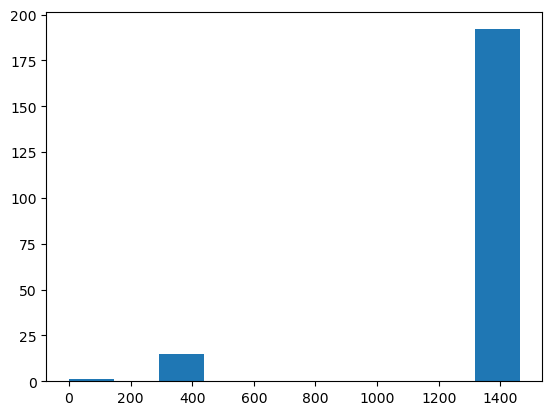

In [57]:
plt.hist(df['col_from_nn'])

In [79]:
lc_filename = 'lightcurve_ztf_20221020148032_000686_zg_c02_x_0017_3_2655_1908.csv'
lc_filename[51]

'3'

In [83]:
df_from_later = pd.read_csv("/home/3155/inference_star_info_r12_bands")

In [ ]:
lc_filename_w_transient = 'ztf_20221020157697_000640_zi_c04_x_0026'

In [103]:
def get_initial_df_for_lc(lc_filename, tolerance=10):
    df_path = (
    '/lustre/lrspec/ZTF_data/science_extractions/1020/')
    filename_start = lc_filename[11:50]
    quad = lc_filename[51]
    df_filename = filename_start+'.fits.fz'+quad+'alllist'
    print(df_filename)
    df = pd.read_csv(df_path+df_filename)
    #i think we're gonna ignore the "both" for now
    df = df[df['type']!='both']
    #so do we think that row is x and column is y? seems likely
    lc_x_coord = int(lc_filename[53:57])
    #we want col from cnn as our streak column
    detection_col = df['col_from_nn']+10
    df = df[np.abs(lc_x_coord-detection_col)<tolerance]
    return df
    

In [101]:
tolerance=10
df_path = (
'/lustre/lrspec/ZTF_data/science_extractions/1020/')
filename_start = 'ztf_20221020297847_000449_zr_c05_x_0006'
quad = '4'
df_filename = filename_start+'.fits.fz'+quad+'alllist'
print(df_filename)
df = pd.read_csv(df_path+df_filename)
#i think we're gonna ignore the "both" for now
df = df[df['type']!='both']
#so do we think that row is x and column is y? seems likely
lc_x_coord = int(1218)
#we want col from cnn as our streak column
detection_col = df['col_from_nn']+10
df = df[np.abs(lc_x_coord-detection_col)<tolerance]


ztf_20221020297847_000449_zr_c05_x_0006.fits.fz4alllist


In [102]:
df

,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size
0,0,ztf_20221020297847_000449_zr_c05_x_0006.,pos,13.000000,1208.750000,4
4,4,ztf_20221020297847_000449_zr_c05_x_0006.,pos,655.625000,1208.750000,8
6,6,ztf_20221020297847_000449_zr_c05_x_0006.,pos,1395.000000,1209.000000,1
7,7,ztf_20221020297847_000449_zr_c05_x_0006.,pos,1717.000000,1209.000000,1
9,9,ztf_20221020297847_000449_zr_c05_x_0006.,pos,2243.000000,1207.000000,3
10,10,ztf_20221020297847_000449_zr_c05_x_0006.,pos,2266.500000,1207.000000,2
11,11,ztf_20221020297847_000449_zr_c05_x_0006.,pos,2266.000000,1209.000000,1
12,12,ztf_20221020297847_000449_zr_c05_x_0006.,pos,2343.333333,1209.500000,12
13,13,ztf_20221020297847_000449_zr_c05_x_0006.,pos,2342.000000,1213.000000,3
14,14,ztf_20221020297847_000449_zr_c05_x_0006.,pos,2438.500000,1209.000000,2


In [85]:
df_from_later.iloc[1]

Unnamed: 0.1                                              1
Unnamed: 0                                                1
0                                                         3
1                                                         3
2                                                         3
3                                                        12
4                                                        12
filename           ztf_20221020297847_000449_zr_c05_x_0006.
type                                                    pos
row_from_nn                                     2343.333333
col_from_nn                                          1209.5
detection_size                                         12.0
quadrant                                                  4
sobel_ratio                                        9.809223
snr_center                                         3.095683
snr_max                                             3.14031
snr_min                                 

In [4]:
image_directory = '/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/'
xy_directory = '/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/'
lightcurve_path = '/lustre/lrspec/ZTF_data/lightcurves/1020/'



['ztf_20221020154120_000640_zi_c14_x_0001.fits.fz2alllist',
 'ztf_20221020138241_000686_zi_c16_x_0005.fits.fz4alllist',
 'ztf_20221020157697_000640_zi_c08_x_0015.fits.fz1alllist',
 'ztf_20221020138241_000686_zi_c08_x_0022.fits.fz1alllist',
 'ztf_20221020141806_000686_zi_c06_x_0016.fits.fz2alllist',
 'ztf_20221020148032_000686_zg_c11_x_0005.fits.fz4alllist',
 'ztf_20221020294271_000449_zr_c02_x_0011.fits.fz2alllist',
 'ztf_20221020297847_000449_zr_c07_x_0017.fits.fz1alllist',
 'ztf_20221020294271_000449_zr_c09_x_0019.fits.fz1alllist',
 'ztf_20221020163819_000640_zg_c10_x_0008.fits.fz1alllist',
 'ztf_20221020297847_000449_zr_c08_x_0026.fits.fz2alllist',
 'ztf_20221020294271_000449_zr_c06_x_0028.fits.fz2alllist',
 'ztf_20221020163819_000640_zg_c06_x_0002.fits.fz4alllist',
 'ztf_20221020138241_000686_zi_c13_x_0008.fits.fz3alllist',
 'ztf_20221020157697_000640_zi_c04_x_0001.fits.fz1alllist',
 'ztf_20221020148032_000686_zg_c14_x_0008.fits.fz3alllist',
 'ztf_20221020297847_000449_zr_c10_x_002

In [141]:
def plot_lc_from_csv_with_transient_df(lc_filename, hap=2):
    lightcurve_path = '/lustre/lrspec/ZTF_data/lightcurves/1020/'
    lc_df = pd.read_csv(lightcurve_path+lc_filename)
    plt.plot(lc_df['flux_hap_'+str(hap)], zorder=10)
    transients_df = get_initial_df_for_lc(lc_filename, tolerance=10)
    for i, row in transients_df.iterrows():
        # print(row['row_from_nn'])
        plt.axvline(x=(int(row['row_from_nn'])+10),c='red')
    # return lc_df
    

ztf_20221020148032_000686_zg_c16_x_0018.fits.fz4alllist


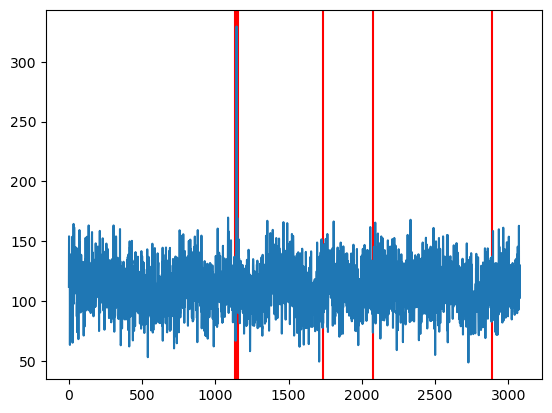

In [142]:
plot_lc_from_csv_with_transient_df('lightcurve_ztf_20221020148032_000686_zg_c16_x_0018_4_2644_2420.csv',3)